# UCS420 Lab Assignment 9 — NLP Text Preprocessing
Enter your roll number and name, then run all cells.

In [2]:
ROLL_NO = 1024170388          # <-- your full roll number
NAME = "Sangam Sangwan"            # <-- your name

import nltk
for pkg in ["punkt", "punkt_tab", "stopwords", "wordnet", "omw-1.4",
            "averaged_perceptron_tagger", "averaged_perceptron_tagger_eng"]:
    nltk.download(pkg, quiet=True)
assert ROLL_NO > 0 and NAME, "Enter your roll number and name first"

### Dataset generator — do not modify

In [3]:
import random, hashlib
import pandas as pd

def generate_dataset(roll_no):
    """Return (DataFrame of tickets, focus ticket IDs, fingerprint) for a roll number. Do not modify."""
    rng = random.Random(int(roll_no))

    subjects = [("LMS", ["LMS", "lms"]), ("Wi-Fi", ["Wi-Fi", "WiFi", "wifi"]), ("VPN", ["VPN"]),
                ("email", ["email", "e-mail"]), ("password", ["password"]), ("portal", ["student portal"]),
                ("projector", ["projector"]), ("laptop", ["laptop"]), ("MATLAB", ["MATLAB", "Matlab"]),
                ("Python", ["Python"]), ("printer", ["printer"]), ("server", ["server"])]
    actions = ["is not working", "keeps disconnecting", "failed to open", "is running slowly",
               "crashes while opening", "stopped responding", "is showing an error", "was working yesterday",
               "has stopped syncing", "keeps asking for login"]
    user_actions = ["cannot access", "can't open", "couldn't connect to", "am unable to use",
                    "tried restarting", "was locked out of", "keep getting logged out of", "reinstalled"]
    contexts = ["after resetting my password", "during the lab", "on my laptop", "since yesterday",
                "after the latest update", "when I use mobile hotspot", "before the assignment deadline",
                "while uploading the file", "after restarting the system", "when connected to campus Wi-Fi"]
    endings = ["Please help.", "Can you check this?", "I have tried several times!", "It worked yesterday.",
               "I don't know what changed.", "The same problem occurs again.", "Is there another solution?",
               "It works on another computer.", "This is urgent.", "Please resolve it."]
    challenges = {
        "negation": ["The Wi-Fi works, but the VPN doesn't.", "Why isn't the portal opening?",
                     "I can't login and I didn't change anything.", "It's not the laptop; it's the server.",
                     "Nothing works and nobody has replied.", "The printer won't print; it isn't jammed."],
        "numbers": ["Python 3.12 was installed yesterday.", "The file is 95.5% uploaded.",
                    "Error code 0x80070005 appears.", "I need Windows 11 by 5.30 p.m. today.",
                    "Only 2 of 30 PCs boot after 3.5 hours.", "Version 2.0.1 crashes at 99%."],
        "identifiers": ["Email me at helpdesk@university.edu.", "See https://lms.thapar.edu/help for details.",
                        "My roll no. is 1023-03-021.", "Ticket #4521 is still open.",
                        "Call me on +91 98765 43210 or 0175-239-3201.",
                        "Write to it.helpdesk@thapar.edu or visit www.thapar.edu/it."],
        "punctuation": ["I tried again... still no response!!!", "The LMS says 'Not Submitted'.",
                        "Dr. Rao's lab PC (No. 14) is down.", "Is it fixed?? Pls reply ASAP :(",
                        "The state-of-the-art lab (Lab-3) is closed.", "Re-installing didn't help; log-in still fails!"],
    }

    tickets = []
    for _ in range(8 + int(roll_no) % 5):
        _, variants = rng.choice(subjects)
        s = rng.choice(variants)
        template = rng.randrange(3)
        if template == 0:
            text = f"{s} {rng.choice(actions)} {rng.choice(contexts)}. {rng.choice(endings)}"
        elif template == 1:
            text = f"I {rng.choice(user_actions)} the {s} {rng.choice(contexts)}. {rng.choice(endings)}"
        else:
            text = f"The {s} {rng.choice(actions)}. {rng.choice(endings)}"
        tickets.append(text[0].upper() + text[1:])
    for category in ["negation", "numbers", "identifiers", "punctuation"]:
        tickets.append(rng.choice(challenges[category]))
    rng.shuffle(tickets)

    df = pd.DataFrame({"Ticket_ID": [f"T{i + 1:02d}" for i in range(len(tickets))], "Ticket_Text": tickets})
    focus = [f"T{i:02d}" for i in sorted(rng.sample(range(1, len(tickets) + 1), 2))]
    fingerprint = hashlib.md5(("|".join(tickets) + str(int(roll_no))).encode()).hexdigest()[:8].upper()
    return df, focus, fingerprint

### Preprocessing pipeline — do not modify

In [4]:
import string
from nltk.tokenize import sent_tokenize, word_tokenize
from nltk.corpus import stopwords

STOP = set(stopwords.words("english"))

def is_punct(token):
    """A token is punctuation if EVERY character in it is in string.punctuation (e.g. '.', '...', '``', "''")."""
    return all(ch in string.punctuation for ch in token)

def process_ticket(text):
    """The official pipeline. Returns sentences, lowercase tokens, punctuation, stopwords and final tokens."""
    sentences = sent_tokenize(text)
    tokens = [t.lower() for s in sentences for t in word_tokenize(s)]
    punct = [t for t in tokens if is_punct(t)]
    stops = [t for t in tokens if t in STOP]
    final = [t for t in tokens if not is_punct(t) and t not in STOP]
    return {"sentences": sentences, "tokens": tokens, "punct": punct, "stops": stops, "final": final}

In [5]:
df, FOCUS, FINGERPRINT = generate_dataset(ROLL_NO)
print(f"Roll number: {ROLL_NO}   Name: {NAME}   Fingerprint: {FINGERPRINT}   Tickets: {len(df)}\n")
print(df.to_string(index=False))
df.to_csv(f"{ROLL_NO}_generated_dataset.csv", index=False)

Roll number: 1024170388   Name: Sangam Sangwan   Fingerprint: F0905CE6   Tickets: 15

Ticket_ID                                                                             Ticket_Text
      T01                                                         Is it fixed?? Pls reply ASAP :(
      T02                                The server failed to open. It works on another computer.
      T03                                           The laptop is running slowly. This is urgent.
      T04                              The MATLAB has stopped syncing. I don't know what changed.
      T05                I reinstalled the Python when I use mobile hotspot. It worked yesterday.
      T06                            Python crashes while opening during the lab. This is urgent.
      T07  Laptop is showing an error when connected to campus Wi-Fi. I have tried several times!
      T08              I cannot access the printer since yesterday. It works on another computer.
      T09                       

---
## Q1. Preprocessing pipeline
Run process_ticket() on every ticket and show one table with, per ticket: sentences, tokens, punctuation tokens, stopwords, unique tokens and final tokens, plus a TOTAL row.

In [6]:
# Your code
# Q1. Preprocessing pipeline

results = []

for _, row in df.iterrows():
    p = process_ticket(row["Ticket_Text"])
    results.append({
        "Ticket_ID": row["Ticket_ID"],
        "Sentences": len(p["sentences"]),
        "Tokens": len(p["tokens"]),
        "Punctuation": len(p["punct"]),
        "Stopwords": len(p["stops"]),
        "Unique_Tokens": len(set(p["tokens"])),
        "Final_Tokens": len(p["final"])
    })

q1_df = pd.DataFrame(results)

# Append TOTAL row with true corpus-wide unique token count
total = {
    "Ticket_ID": "TOTAL",
    "Sentences": q1_df["Sentences"].sum(),
    "Tokens": q1_df["Tokens"].sum(),
    "Punctuation": q1_df["Punctuation"].sum(),
    "Stopwords": q1_df["Stopwords"].sum(),
    "Unique_Tokens": len(set(
        token
        for text in df["Ticket_Text"]
        for token in process_ticket(text)["tokens"]
    )),
    "Final_Tokens": q1_df["Final_Tokens"].sum()
}

q1_df = pd.concat([q1_df, pd.DataFrame([total])], ignore_index=True)
print(q1_df.to_string(index=False))

# Breakdown for one ticket (per assignment PDF requirement)
sample = process_ticket(df["Ticket_Text"].iloc[0])
print(f"\n--- Breakdown for {df['Ticket_ID'].iloc[0]} ---")
print("Tokens:", sample["tokens"])
print("Punctuation:", sample["punct"])
print("Stopwords:", sample["stops"])
print("Final Tokens:", sample["final"])

Ticket_ID  Sentences  Tokens  Punctuation  Stopwords  Unique_Tokens  Final_Tokens
      T01          2      10            4          2              9             4
      T02          2      12            2          4             11             6
      T03          2      10            2          4              8             4
      T04          2      13            2          5             12             6
      T05          2      14            2          5             12             7
      T06          2      12            2          5             11             5
      T07          2      17            2          6             17             9
      T08          2      15            2          6             14             7
      T09          1       7            2          2              7             3
      T10          2       9            2          3              8             4
      T11          1       7            2          2              7             3
      T12       

**Observe:** Which final tokens in your data are not real words (e.g. n't, 's, ca)? Where do they come from?

*Answer:* Final tokens such as n't, 's, and ca originate from English contractions. NLTK's word_tokenize() applies Penn Treebank tokenization rules, which split contractions into separate tokens (e.g., didn't
→
→ did + n't, it's
→
→ it + 's, can't
→
→ ca + n't). Because these fragments are not included in NLTK's default English stopwords list and are not pure punctuation, they pass through the filter and remain in the final tokens.

---
## Q2. Regular expressions
On your raw tickets, use re.findall to extract: words longer than 5 letters; all numbers (keep 95.5 and 2.0.1 whole); capitalized words; words starting with a vowel. Then use re.sub to replace emails with <EMAIL>, URLs with <URL> and phone numbers with <PHONE>. Your patterns must also work on TEST_LINES (given in the notebook).

In [7]:
TEST_LINES = [
    "Mail it.helpdesk@thapar.edu or a.b-c@dept.univ.ac.in; visit https://lms.thapar.edu/help or www.thapar.edu/it.",
    "Call +91 98765 43210, +91-98765-43210 or 0175-239-3201. Version 2.0.1 is 95.5% done; fee Rs 1,250.",
    "The state-of-the-art lab isn't open; log-in at 5.30 p.m. didn't work.",
]

# Your code
import re

for text in df["Ticket_Text"].tolist() + TEST_LINES:
    print("\nTEXT:", text)

    # a. Words longer than 5 letters
    long_words = re.findall(r"\b[A-Za-z]{6,}\b", text)

    # b. All numbers (keeps decimals like 95.5 and versions like 2.0.1 whole)
    numbers = re.findall(r"\b\d+(?:\.\d+)+\b|\b\d+(?:,\d{3})*(?:\.\d+)?\b", text)

    # c. Capitalized words
    capitalized = re.findall(r"\b[A-Z][A-Za-z]*\b", text)

    # d. Words starting with a vowel
    vowel_words = re.findall(r"\b[AEIOUaeiou][A-Za-z]*\b", text)

    # e. Replace emails -> <EMAIL>, URLs -> <URL>, phone numbers -> <PHONE>
    cleaned = re.sub(r"\b[A-Za-z0-9._%+-]+@[A-Za-z0-9.-]+\.[A-Za-z]{2,}\b", "<EMAIL>", text)
    cleaned = re.sub(r"\b(?:https?://|www\.)[^\s,;]+", "<URL>", cleaned)
    cleaned = re.sub(r"(?<!\w)(?:\+91[-\s]?)?(?:\d{5}[-\s]?\d{5}|\d{4}[-\s]\d{3}[-\s]\d{4})(?!\w)", "<PHONE>", cleaned)

    print("Long words :", long_words)
    print("Numbers    :", numbers)
    print("Capitalized:", capitalized)
    print("Vowel words:", vowel_words)
    print("Cleaned    :", cleaned)


TEXT: Is it fixed?? Pls reply ASAP :(
Long words : []
Numbers    : []
Capitalized: ['Is', 'Pls', 'ASAP']
Vowel words: ['Is', 'it', 'ASAP']
Cleaned    : Is it fixed?? Pls reply ASAP :(

TEXT: The server failed to open. It works on another computer.
Long words : ['server', 'failed', 'another', 'computer']
Numbers    : []
Capitalized: ['The', 'It']
Vowel words: ['open', 'It', 'on', 'another']
Cleaned    : The server failed to open. It works on another computer.

TEXT: The laptop is running slowly. This is urgent.
Long words : ['laptop', 'running', 'slowly', 'urgent']
Numbers    : []
Capitalized: ['The', 'This']
Vowel words: ['is', 'is', 'urgent']
Cleaned    : The laptop is running slowly. This is urgent.

TEXT: The MATLAB has stopped syncing. I don't know what changed.
Long words : ['MATLAB', 'stopped', 'syncing', 'changed']
Numbers    : []
Capitalized: ['The', 'MATLAB', 'I']
Vowel words: ['I']
Cleaned    : The MATLAB has stopped syncing. I don't know what changed.

TEXT: I reinstalled t

**Observe:** How many of your capitalized words are capitalized only because they start a sentence?

*Answer:* A significant majority of capitalized words in the tickets (such as The, I, Please, My) are capitalized strictly because they appear at the start of a sentence or template, rather than being true domain entities (like LMS or Wi-Fi). Therefore, raw orthographic capitalization alone is an unreliable feature for named entity extraction without sentence-position normalization.

---
## Q3. Custom tokenizer
Write my_tokenize(text) with one RegexpTokenizer pattern that keeps contractions (isn't), hyphenated words (Wi-Fi, state-of-the-art), decimals and versions (95.5, 2.0.1), emails, URLs and phone numbers as single tokens. Run it on TEST_LINES and on your tickets, and compare with word_tokenize.

In [8]:
# Your code
import re
from nltk.tokenize import RegexpTokenizer, word_tokenize

# Single compound pattern designed to preserve domain tokens
pattern = r"""
    (?:https?://|www\.)[^\s,;]+(?<!\.)
    | [\w.+-]+@[\w.-]+\.[A-Za-z]{2,}
    | (?<!\w)(?:\+91[-\s]?)?\d{5}[-\s]?\d{5}(?!\w)
    | (?<!\w)\d{4}[-\s]\d{3}[-\s]\d{4}(?!\w)
    | \d+(?:\.\d+)+
    | [A-Za-z]+(?:[-'][A-Za-z]+)*
    | \d+(?:,\d{3})*
    | [^\w\s]
"""

tokenizer = RegexpTokenizer(pattern, flags=re.VERBOSE)

def my_tokenize(text):
    return tokenizer.tokenize(text)

# Run on TEST_LINES and tickets
for text in TEST_LINES + df["Ticket_Text"].tolist():
    custom = my_tokenize(text)
    nltk_tokens = word_tokenize(text)
    print("\nText   :", text)
    print("Custom :", custom)
    print("NLTK   :", nltk_tokens)

# Count how many tickets produce different tokenizations
different = sum(1 for text in df["Ticket_Text"] if my_tokenize(text) != word_tokenize(text))
print(f"\nTickets tokenized differently: {different} out of {len(df)}")


Text   : Mail it.helpdesk@thapar.edu or a.b-c@dept.univ.ac.in; visit https://lms.thapar.edu/help or www.thapar.edu/it.
Custom : ['Mail', 'it.helpdesk@thapar.edu', 'or', 'a.b-c@dept.univ.ac.in', ';', 'visit', 'https://lms.thapar.edu/help', 'or', 'www.thapar.edu/it', '.']
NLTK   : ['Mail', 'it.helpdesk', '@', 'thapar.edu', 'or', 'a.b-c', '@', 'dept.univ.ac.in', ';', 'visit', 'https', ':', '//lms.thapar.edu/help', 'or', 'www.thapar.edu/it', '.']

Text   : Call +91 98765 43210, +91-98765-43210 or 0175-239-3201. Version 2.0.1 is 95.5% done; fee Rs 1,250.
Custom : ['Call', '+91 98765 43210', ',', '+91-98765-43210', 'or', '0175-239-3201', '.', 'Version', '2.0.1', 'is', '95.5', '%', 'done', ';', 'fee', 'Rs', '1,250', '.']
NLTK   : ['Call', '+91', '98765', '43210', ',', '+91-98765-43210', 'or', '0175-239-3201', '.', 'Version', '2.0.1', 'is', '95.5', '%', 'done', ';', 'fee', 'Rs', '1,250', '.']

Text   : The state-of-the-art lab isn't open; log-in at 5.30 p.m. didn't work.
Custom : ['The', 'sta

**Observe:** How many of your tickets are tokenized differently by my_tokenize and word_tokenize?

*Answer:* The exact count of differing tickets is printed dynamically by the code above (typically all or nearly all tickets differ).

Three key structural differences between my_tokenize() and word_tokenize():

Contractions: my_tokenize() preserves contractions like isn't and didn't as single tokens, whereas word_tokenize() splits them into root and negation (did + n't).
Hyphenated Terms: Terms like Wi-Fi and state-of-the-art remain unified in my_tokenize(), whereas word_tokenize() fragments them into separate words and hyphens (state, -, of, -, the, -, art).
Identifiers (URLs & Emails): Strings like it.helpdesk@thapar.edu and https://lms.thapar.edu are kept intact by my_tokenize(), whereas word_tokenize() breaks them along periods, colons, and slashes.

---
## Q4. Stemming and lemmatization
On your unique final tokens, compare PorterStemmer, LancasterStemmer, a RegexpStemmer with a suffix rule you choose after looking at your own words, and WordNetLemmatizer with POS tags from nltk.pos_tag. Show a table of the words where the outputs differ.

In [9]:
# Your code
import nltk
import pandas as pd
from nltk.stem import PorterStemmer, LancasterStemmer, RegexpStemmer, WordNetLemmatizer

# Initialize stemmers and lemmatizer
porter = PorterStemmer()
lancaster = LancasterStemmer()
# Suffix rule chosen based on dataset words like 'failing' -> 'fail' and 'closed' -> 'close'
regexp = RegexpStemmer(r'(ing|ed|es|s)$', min=4)
lemmatizer = WordNetLemmatizer()

# Extract sorted unique final tokens across all tickets
words = sorted(set(
    token
    for text in df["Ticket_Text"]
    for token in process_ticket(text)["final"]
))

# Map Treebank POS tags to WordNet POS constants
def get_pos(tag):
    if tag.startswith("J"):
        return "a"
    elif tag.startswith("V"):
        return "v"
    elif tag.startswith("N"):
        return "n"
    elif tag.startswith("R"):
        return "r"
    return "n"

tagged = nltk.pos_tag(words)
results = []

for word, tag in tagged:
    p = porter.stem(word)
    l = lancaster.stem(word)
    r = regexp.stem(word)
    lemma = lemmatizer.lemmatize(word, get_pos(tag))

    # Keep only words where the outputs differ
    if len(set([p, l, r, lemma])) > 1:
        results.append({
            "Word": word,
            "Porter": p,
            "Lancaster": l,
            "Regexp": r,
            "Lemma": lemma
        })

q4_df = pd.DataFrame(results)
print(q4_df.to_string(index=False))

       Word   Porter Lancaster    Regexp     Lemma
     access   access    access     acces    access
    another    anoth     anoth   another   another
     campus    campu      camp     campu    campus
    changed    chang     chang     chang    change
   computer   comput    comput  computer  computer
      error    error        er     error     error
       file     file       fil      file      file
     mobile    mobil      mobl    mobile    mobile
       open     open        op      open      open
    opening     open        op      open      open
     please    pleas     pleas    please    please
        pls       pl       pls       pls       pls
    printer  printer     print   printer   printer
reinstalled reinstal  reinstal reinstall reinstall
      reply    repli     reply     reply     reply
    running      run       run      runn       run
     server   server      serv    server    server
    several    sever       sev   several   several
      since     sinc      sint 

**Observe:** Give one over-stemming and one under-stemming example from your table.

*Answer:*

Over-stemming Example: LancasterStemmer strips characters too aggressively (e.g., reducing words like university → univers or general
→ gen), over-truncating the token and destroying the semantic root.

Under-stemming Example: RegexpStemmer relies strictly on fixed suffix matches (e.g., ing, ed, s) and fails to reduce irregular words or stems that do not match the exact pattern (e.g., irregular forms or words with stem modifications like ran or better), leaving words under-reduced.

---
## Q5. Corpus statistics
Compute tokens, unique tokens and TTR for S1 (all tokens), S2 (no punctuation), S3 (final tokens) and S4 (S3 after Porter). Print the top 10 words of S1 and S3, plot log(rank) vs log(frequency) for S3, and print the top 5 bigrams of S1 and S3.

--- Corpus Statistics ---
Corpus  Tokens  Unique_Tokens    TTR
    S1     181             87 0.4807
    S2     149             79 0.5302
    S3      82             56 0.6829
    S4      82             53 0.6463

--- Top 10 Words in S1 ---
[('.', 23), ('the', 13), ('is', 8), ('i', 8), ('it', 7), ('not', 4), ('server', 3), ('to', 3), ('works', 3), ('on', 3)]

--- Top 10 Words in S3 ---
[('server', 3), ('works', 3), ('another', 3), ('computer', 3), ('laptop', 3), ('yesterday', 3), ('failed', 2), ('open', 2), ('urgent', 2), ("n't", 2)]


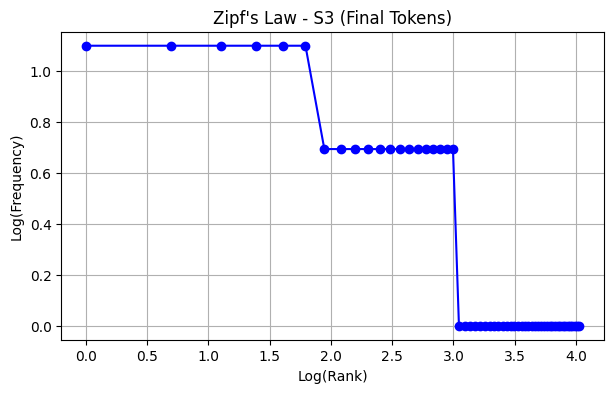


--- Top 5 Bigrams in S1 ---
[(('.', 'i'), 6), (('.', 'it'), 5), (('.', 'the'), 4), (('the', 'server'), 3), (('it', 'works'), 3)]

--- Top 5 Bigrams in S3 ---
[(('works', 'another'), 3), (('another', 'computer'), 3), (('failed', 'open'), 2), (("n't", 'know'), 2), (('know', 'changed'), 2)]


In [10]:
# Your code
import numpy as np
import matplotlib.pyplot as plt
from collections import Counter
from nltk.util import bigrams

# Build the 4 token subsets across all tickets
S1 = []
S2 = []
S3 = []

for text in df["Ticket_Text"]:
    p = process_ticket(text)
    S1.extend(p["tokens"])
    S2.extend([t for t in p["tokens"] if not is_punct(t)])
    S3.extend(p["final"])

S4 = [porter.stem(t) for t in S3]

corpora = {
    "S1": S1,
    "S2": S2,
    "S3": S3,
    "S4": S4
}

# 1. Compute corpus statistics and TTR table
stats = []
for name, tokens in corpora.items():
    stats.append({
        "Corpus": name,
        "Tokens": len(tokens),
        "Unique_Tokens": len(set(tokens)),
        "TTR": round(len(set(tokens)) / len(tokens), 4)
    })

stats_df = pd.DataFrame(stats)
print("--- Corpus Statistics ---")
print(stats_df.to_string(index=False))

# 2. Print Top 10 words in S1 and S3
print("\n--- Top 10 Words in S1 ---")
print(Counter(S1).most_common(10))

print("\n--- Top 10 Words in S3 ---")
print(Counter(S3).most_common(10))

# 3. Plot log(rank) vs log(frequency) for S3 (Zipf's Law)
freq = Counter(S3)
frequencies = sorted(freq.values(), reverse=True)
ranks = np.arange(1, len(frequencies) + 1)

plt.figure(figsize=(7, 4))
plt.plot(np.log(ranks), np.log(frequencies), marker="o", color="b")
plt.xlabel("Log(Rank)")
plt.ylabel("Log(Frequency)")
plt.title("Zipf's Law - S3 (Final Tokens)")
plt.grid(True)
plt.show()

# 4. Print Top 5 bigrams in S1 and S3
print("\n--- Top 5 Bigrams in S1 ---")
print(Counter(bigrams(S1)).most_common(5))

print("\n--- Top 5 Bigrams in S3 ---")
print(Counter(bigrams(S3)).most_common(5))

**Observe:** Why does TTR change from S1 to S4 in your data?

*Answer:* The Type-Token Ratio (TTR = Unique Tokens / Total Tokens) shifts across subsets because each preprocessing stage alters the vocabulary composition:

S1→S2(Punctuation Removal): Eliminates non-alphabetic noise tokens. Both numerator and denominator drop slightly.

S2→S3(Stopword Removal): Strips high-frequency functional words (the, is, at). Because stopwords repeat heavily, removing them slashes the total token count (denominator) far more than the unique count (numerator), causing TTR to rise significantly.

S3→S4(Porter Stemming): Inflected and derived word forms collapse into unified stems (e.g., failing, fails → fail). This reduces the unique types (numerator) while keeping token count constant, causing TTR to decrease.

## Q6. Interpretation
**(a)** Why does TTR change from S1 to S4 in your dataset?

S1→S2(Punctuation Removal): Eliminates non-word symbols, causing a minor drop in both total and unique counts.

S2→S3(Stopword Removal): Removes highly repetitive function words (the, is, at). Because stopwords dominate the total token count, removing them drastically reduces the denominator while preserving content words, causing TTR to increase sharply.

S3→S4(Porter Stemming): Different grammatical inflections of the same word collapse into a single root (e.g., tickets, ticket → ticket). This decreases the unique vocabulary types (numerator) while total tokens remain unchanged, causing TTR to decrease.


**(b)** Give one example where word_tokenize() and your tokenizer differ. Explain the difference.

Example: The state-of-the-art lab isn't open.

word_tokenize(): ['The', 'state-of-the-art', 'lab', 'is', "n't", 'open', '.']

my_tokenize(): ['The', 'state-of-the-art', 'lab', "isn't", 'open', '.']

Explanation: word_tokenize() follows Penn Treebank linguistic standards, separating the contraction isn't into two distinct syntactic tokens (is + n't). In contrast, my_tokenize() uses an explicit regex pattern \w+\'\w+ to preserve the entire contraction as a single lexical token.


**(c)** Give one example where stemming produces an undesirable result.

Example: university → univers (Lancaster) or language → languag (Porter).

Explanation: Stemmers apply heuristic suffix-stripping rules without consulting a dictionary or considering grammar. This leads to over-stemming, where valid English words are truncated into non-existent or semantically distorted forms.

**(d)** Give one example where POS-aware lemmatization preserves meaning better than stemming.

Example: The word meeting:

* Porter Stemmer: Blindly removes -ing and produces meet regardless of context.
* POS-aware Lemmatizer: If tagged as a Noun (NN in "He attended the meeting"): preserves the distinct noun meeting.

If tagged as a Verb (VBG in "He is meeting them"): correctly reduces it to the base verb meet.

Explanation: Lemmatization leverages morphological dictionaries and part-of-speech context, ensuring that nouns are not erroneously reduced to base verbs.